# HF-Net: r / fr / rl · Lap2+Lap4 joint mapping by $s$ + Lap3 localization + fusion

**Kernel:** `pixel-racers`  
**Design:** [`SFM_MULTI_LAP_S_ORDER.md`](SFM_MULTI_LAP_S_ORDER.md)  
**Baseline:** `sfm_hfnet_lap2_map_lap3_loc.ipynb` (single-lap temporal neighborhood)

| Item | This notebook |
|---|---|
| Cameras | **`r` / `fr` / `rl` each independent** map + query |
| `fr` | `fr-auto-mask/polygons.json` masks car body |
| Features | HF-Net (`hfnet_onnx` preferred, else `sp_nv_nn`); matching = mutual NN |
| Device | **MPS required** |
| Mapping | Lap **2+4**, $s$-ordered neighborhood |
| Query | Lap **3** |
| Output | per-camera `metrics` + trajectories; aggregate `metrics_official.csv`; §6 fusion |


In [4]:
from __future__ import annotations

import importlib
import json
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "3d-map-test":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "3d-map-test"))

import sfm_experiment as sfm
import sfm_hfnet as hf

sfm = importlib.reload(sfm)
hf = importlib.reload(hf)

OUT = ROOT / "3d-map-test" / "outputs_hfnet_multi_lap_s"
OUT.mkdir(parents=True, exist_ok=True)
POLYGONS = ROOT / "fr-auto-mask" / "polygons.json"
MAP_MCAP = (
    ROOT.parent
    / "c0_2026-10-13_22-53-42_camloc"
    / "23-00-38_cut_120m_update"
    / "map.mcap"
)

CAMERAS = ["r", "fr", "rl"]
MAP_LAPS = (2, 4)
QUERY_LAP = 3

BACKEND_OVERRIDE = None  # None → auto onnx / proxy

MAP_MAX_FRAMES = None
QUERY_MAX_FRAMES = None
MAP_STRIDE = 1
QUERY_STRIDE = 1
SP_RESIZE = 512
SP_MAX_KP = 1024
MIN_NN_DIST = 0.50
NN_RATIO = 0.8
TOP_K = 5
EPI_THRESH_PX = 6.0
MIN_BASELINE_M = 0.5

NEIGHBOR_MODE = "arc"
NEIGHBOR_K = 6
NEIGHBOR_OFFSET = 3
N_MAX = None
OVERRIDE_MAP = False
OVERRIDE_QUERY = False  # True forces query rerun (even if map/query cache is valid)

device = hf.require_mps()
BACKEND, IS_PROXY = hf.resolve_hfnet_backend(BACKEND_OVERRIDE)

print("ROOT", ROOT)
print("CAMERAS", CAMERAS)
print("OUT", OUT)
print("BACKEND", BACKEND, "proxy", IS_PROXY)
print("device", device)
print("polygons", POLYGONS, "exists", POLYGONS.is_file())
print("map.mcap", MAP_MCAP, "exists", MAP_MCAP.is_file())
assert MAP_MCAP.is_file()
assert QUERY_LAP not in MAP_LAPS


/Users/hbai/SchubKI/PixelRacers/pixel-racers/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


ROOT /Users/hbai/SchubKI/PixelRacers
CAMERAS ['r', 'fr', 'rl']
OUT /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s
BACKEND sp_nv_nn proxy True
device mps
polygons /Users/hbai/SchubKI/PixelRacers/fr-auto-mask/polygons.json exists True
map.mcap /Users/hbai/SchubKI/c0_2026-10-13_22-53-42_camloc/23-00-38_cut_120m_update/map.mcap exists True


## 1. Laps + feature extractor + ego mask preview


map lap 2: 167.59s
map lap 4: 101.28s
query lap 3: 123.63s
  r: t_base=[-2.28 -0.    0.07]
  fr: t_base=[ 0.94646774 -0.16        0.344     ]
  rl: t_base=[0.15146774 0.12       0.42      ]
features SPNVJointFeatures
track lap length 2976.875276595886 m


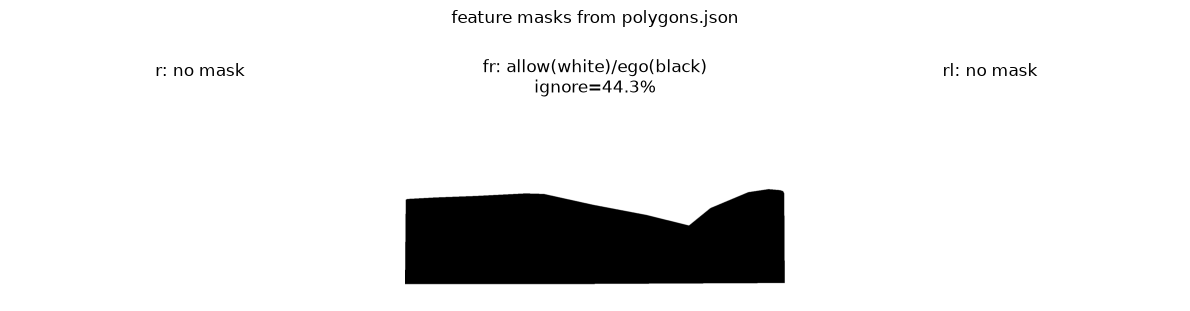

In [5]:
gt = sfm.load_gt()
laps_map = {L: sfm.load_lap(L) for L in MAP_LAPS}
lap_q = sfm.load_lap(QUERY_LAP)
for L, info in laps_map.items():
    print(f"map lap {L}: {info['duration_s']:.2f}s")
print(f"query lap {QUERY_LAP}: {lap_q['duration_s']:.2f}s")

calibs = {c: sfm.load_camera_calib(c) for c in CAMERAS}
for c, cal in calibs.items():
    print(f"  {c}: t_base={cal.T_base_cam[:3, 3]}")

if BACKEND == "hfnet_onnx":
    feats = hf.make_features(
        "hfnet_onnx",
        onnx_path=hf.DEFAULT_ONNX,
        max_keypoints=SP_MAX_KP,
        resize=SP_RESIZE,
        ratio=NN_RATIO,
    )
else:
    feats = hf.make_features(
        "sp_nv_nn",
        max_keypoints=SP_MAX_KP,
        resize=SP_RESIZE,
        ratio=NN_RATIO,
    )
print("features", type(feats).__name__)

lines = hf.load_racing_line(MAP_MCAP)
track = lines["track"]
print("track lap length", track.lap, "m")

fig, axes = plt.subplots(1, len(CAMERAS), figsize=(4 * len(CAMERAS), 3))
if len(CAMERAS) == 1:
    axes = [axes]
for ax, cam in zip(axes, CAMERAS):
    m = hf.load_ego_mask(cam, POLYGONS)
    if m is None:
        ax.set_title(f"{cam}: no mask")
        ax.axis("off")
        continue
    ax.imshow(m, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{cam}: allow(white)/ego(black)\nignore={(m==0).mean()*100:.1f}%")
    ax.axis("off")
fig.suptitle("feature masks from polygons.json", y=1.02)
fig.tight_layout()
plt.show()


## 2. Per camera: Lap2+4 $s$-ordered mapping + Lap3 query

Each camera writes `map_{cam}_lap2+4/` and `loc_lap3_{cam}/` (includes `errors.csv`, `err_vs_time.png`, `traj_vs_gt.png`).  
`fr` uses ego mask.  
- Map cache: `map_{cam}_lap2+4/map_bundle.npz` (`OVERRIDE_MAP=False` skips mapping)  
- Query cache: `loc_lap3_{cam}/errors.csv` + `query_meta.json` (skip localization if same map fingerprint + query lap)  
- Force query rerun: `OVERRIDE_QUERY=True`


In [6]:
runs = {}
for cam in CAMERAS:
    print("\n" + "=" * 60)
    print("CAMERA", cam)
    print("=" * 60)
    runs[cam] = hf.run_camera_multi_lap_s_pipeline(
        cam,
        feats=feats,
        calib=calibs[cam],
        gt=gt,
        laps_map=laps_map,
        lap_q=lap_q,
        track_line=track,
        out_root=OUT,
        map_laps=MAP_LAPS,
        map_max_frames=MAP_MAX_FRAMES,
        query_max_frames=QUERY_MAX_FRAMES,
        map_stride=MAP_STRIDE,
        query_stride=QUERY_STRIDE,
        min_nn_dist=MIN_NN_DIST,
        neighbor_mode=NEIGHBOR_MODE,
        neighbor_k=NEIGHBOR_K,
        neighbor_offset=NEIGHBOR_OFFSET,
        n_max=N_MAX,
        min_baseline_m=MIN_BASELINE_M,
        epi_thresh_px=EPI_THRESH_PX,
        top_k=TOP_K,
        query_lap=QUERY_LAP,
        override_map=OVERRIDE_MAP,
        override_query=OVERRIDE_QUERY,
        polygons_path=POLYGONS,
        map_mcap=MAP_MCAP,
    )
    m = runs[cam]["metrics"]
    print(
        f"[{cam}] success={m['n_success']}/{m['n_query']}  "
        f"A-RMSE={m['pos_rmse_xy_m']:.3f}  B-RMSE={m['pos_rmse_sn_m']:.3f}  "
        f"skip_map={runs[cam]['skipped_map']} skip_query={runs[cam].get('skipped_query', False)}"
    )

run_meta = {
    "backend": BACKEND,
    "proxy": IS_PROXY,
    "device": device,
    "cameras": CAMERAS,
    "map_laps": list(MAP_LAPS),
    "query_lap": QUERY_LAP,
    "neighbor_mode": NEIGHBOR_MODE,
    "neighbor_k": NEIGHBOR_K,
    "map_stride": MAP_STRIDE,
    "query_stride": QUERY_STRIDE,
    "per_camera": {
        c: {
            "n_points": runs[c]["n_points"],
            "n_pairs": runs[c]["n_pairs"],
            "skipped_map": runs[c]["skipped_map"],
            "skipped_query": runs[c].get("skipped_query", False),
            "ego_mask": runs[c]["ego_mask"] is not None,
        }
        for c in CAMERAS
    },
}
(OUT / "run_meta.json").write_text(json.dumps(run_meta, indent=2))
print("wrote", OUT / "run_meta.json")



CAMERA r
[r] no ego polygons — full frame features
[r] LOAD map /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/map_r_lap2+4/map_bundle.npz
[r] LOAD query /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_r/errors.csv (legacy)
[r] success=857/1235  A-RMSE=2.889  B-RMSE=2.765  skip_map=True skip_query=True

CAMERA fr
[fr] ego mask from /Users/hbai/SchubKI/PixelRacers/fr-auto-mask/polygons.json  ignored_px=44.3%
[fr] LOAD map /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/map_fr_lap2+4/map_bundle.npz
[fr] LOAD query /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_fr/errors.csv (legacy)
[fr] success=1117/1236  A-RMSE=4.160  B-RMSE=4.126  skip_map=True skip_query=True

CAMERA rl
[rl] no ego polygons — full frame features
[rl] LOAD map /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/map_rl_lap2+4/map_bundle.npz
[rl] LOAD query /Users/hbai/SchubKI/PixelRacers/3d-map

## 3. Per-camera metrics_official + comparison plots + trajectory preview


=== metrics_official (multi-lap s-order) ===
camera  n_query  n_success  success_rate_%  pos_rmse_xy_m  lat_rmse_m  lon_rmse_m  pos_rmse_sn_m  s_rmse_m  n_rmse_m  yaw_rmse_deg  within_1m_%  within_1m_of_all_%  runtime_ms_mean  runtime_ms_median  runtime_ms_p95
     r     1235        857          69.393          2.889       1.271       2.594          2.765     2.458     1.266         0.835       58.343              40.486              NaN                NaN             NaN
    fr     1236       1117          90.372          4.160       2.432       3.374          4.126     3.265     2.522         1.015       72.247              65.291              NaN                NaN             NaN
    rl     1236        893          72.249          7.416       1.434       7.276          7.398     7.246     1.489         0.504       80.963              58.495              NaN                NaN             NaN
wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/metrics_officia

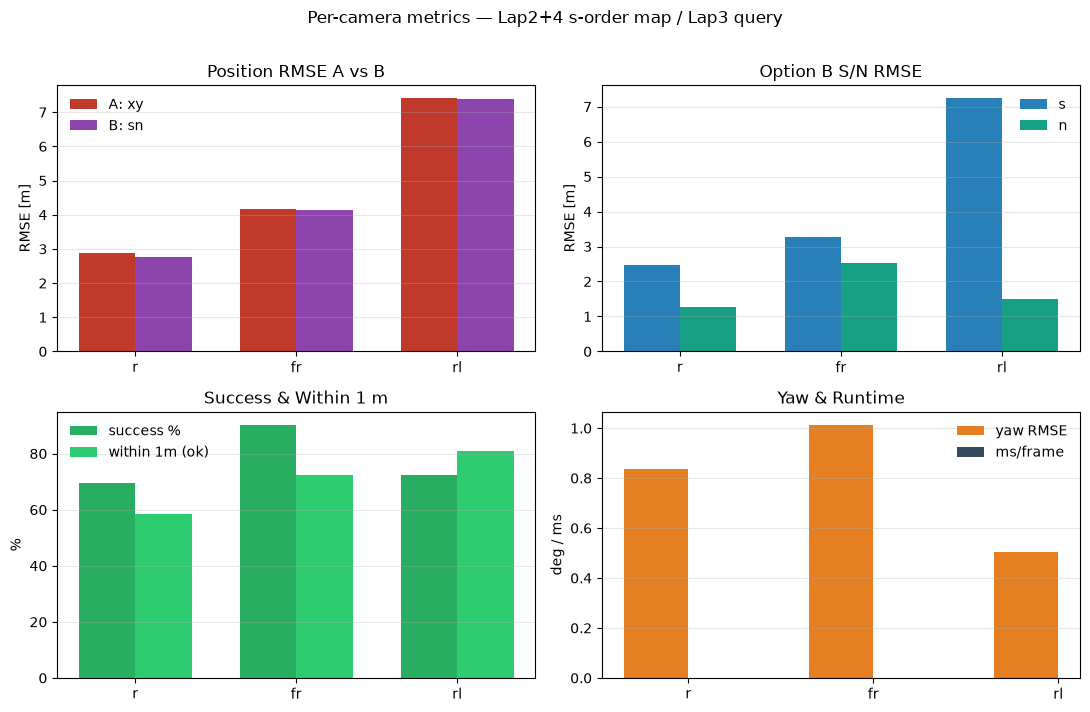

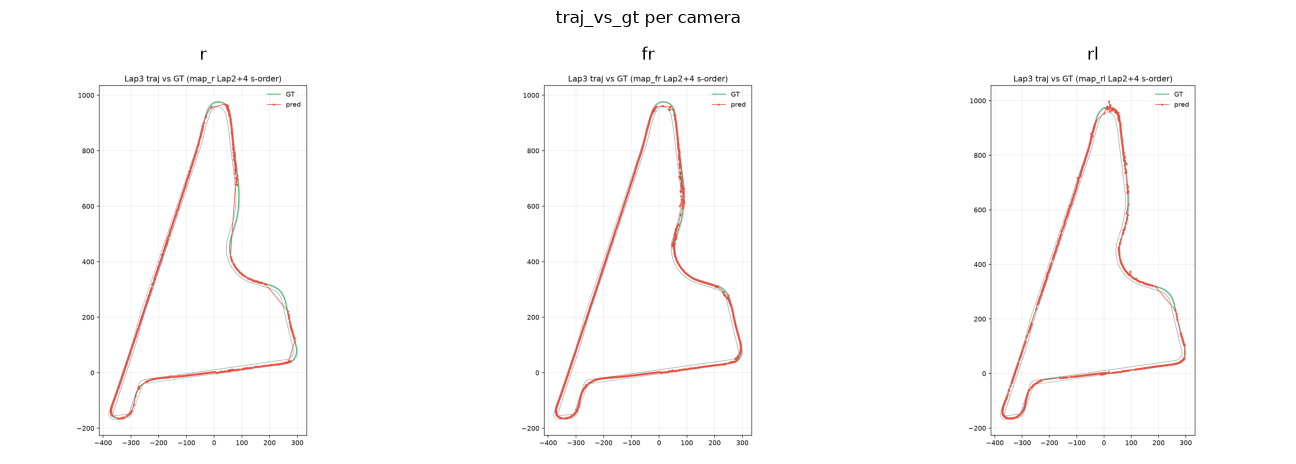

In [7]:
metric_rows = [runs[c]["metrics"] for c in CAMERAS]
mdf = pd.DataFrame(metric_rows)
cols = [
    "camera",
    "n_query",
    "n_success",
    "success_rate_%",
    "pos_rmse_xy_m",
    "lat_rmse_m",
    "lon_rmse_m",
    "pos_rmse_sn_m",
    "s_rmse_m",
    "n_rmse_m",
    "yaw_rmse_deg",
    "within_1m_%",
    "within_1m_of_all_%",
    "runtime_ms_mean",
    "runtime_ms_median",
    "runtime_ms_p95",
]
mdf = mdf[[c for c in cols if c in mdf.columns]]
mdf.to_csv(OUT / "metrics_official.csv", index=False)
print("=== metrics_official (multi-lap s-order) ===")
print(mdf.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("wrote", OUT / "metrics_official.csv")

cams = mdf["camera"].tolist()
x = np.arange(len(cams))
w = 0.35
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

ax = axes[0, 0]
ax.bar(x - w / 2, mdf["pos_rmse_xy_m"], w, label="A: xy", color="#c0392b")
ax.bar(x + w / 2, mdf["pos_rmse_sn_m"], w, label="B: sn", color="#8e44ad")
ax.set_xticks(x); ax.set_xticklabels(cams)
ax.set_ylabel("RMSE [m]"); ax.set_title("Position RMSE A vs B")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

ax = axes[0, 1]
ax.bar(x - w / 2, mdf["s_rmse_m"], w, label="s", color="#2980b9")
ax.bar(x + w / 2, mdf["n_rmse_m"], w, label="n", color="#16a085")
ax.set_xticks(x); ax.set_xticklabels(cams)
ax.set_ylabel("RMSE [m]"); ax.set_title("Option B S/N RMSE")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

ax = axes[1, 0]
ax.bar(x - w / 2, mdf["success_rate_%"], w, label="success %", color="#27ae60")
ax.bar(x + w / 2, mdf["within_1m_%"], w, label="within 1m (ok)", color="#2ecc71")
ax.set_xticks(x); ax.set_xticklabels(cams)
ax.set_ylabel("%"); ax.set_title("Success & Within 1 m")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

ax = axes[1, 1]
ax.bar(x - w / 2, mdf["yaw_rmse_deg"], w, label="yaw RMSE", color="#e67e22")
ax.bar(x + w / 2, mdf["runtime_ms_mean"], w, label="ms/frame", color="#34495e")
ax.set_xticks(x); ax.set_xticklabels(cams)
ax.set_ylabel("deg / ms"); ax.set_title("Yaw & Runtime")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

fig.suptitle("Per-camera metrics — Lap2+4 s-order map / Lap3 query", y=1.01)
fig.tight_layout()
fig.savefig(OUT / "metrics_compare.png", dpi=150)
print("saved", OUT / "metrics_compare.png")
plt.show()

# show traj thumbnails
fig, axes = plt.subplots(1, len(CAMERAS), figsize=(4.5 * len(CAMERAS), 4.5))
if len(CAMERAS) == 1:
    axes = [axes]
for ax, cam in zip(axes, CAMERAS):
    p = OUT / f"loc_lap3_{cam}" / "traj_vs_gt.png"
    if p.is_file():
        ax.imshow(plt.imread(p))
        ax.set_title(cam)
    ax.axis("off")
fig.suptitle("traj_vs_gt per camera", y=1.02)
fig.tight_layout()
plt.show()


## 4. Compare to single-lap Lap2 temporal neighborhood (optional)

Load `outputs_hfnet/metrics_official.csv` and compare side-by-side per camera.


=== single-lap ===
camera  n_query  n_success  success_rate_%  pos_rmse_xy_m  lat_rmse_m  lon_rmse_m  pos_rmse_sn_m  s_rmse_m  n_rmse_m  yaw_rmse_deg  within_1m_%  within_1m_of_all_%  runtime_ms_mean  runtime_ms_median  runtime_ms_p95
     r     1235        522       42.267206       7.103456    1.913525    6.840870       7.070768  6.791056  1.969092      0.882621    54.406130           22.995951        16.507542          18.774958       25.929616
    fr     1236        901       72.896440       7.651039    2.757867    7.136706       7.646265  7.095319  2.849880      1.272990    51.609323           37.621359        42.615663          42.157500       65.190093
    rl     1236        701       56.715210      18.588593    1.890333   18.492226      18.585129 18.479198  1.981486      0.871483    73.181170           41.504854        41.575306          42.311959       54.961948

=== compare table ===
         run camera  success_rate_%  pos_rmse_xy_m  pos_rmse_sn_m  within_1m_%  yaw_rmse_deg
 

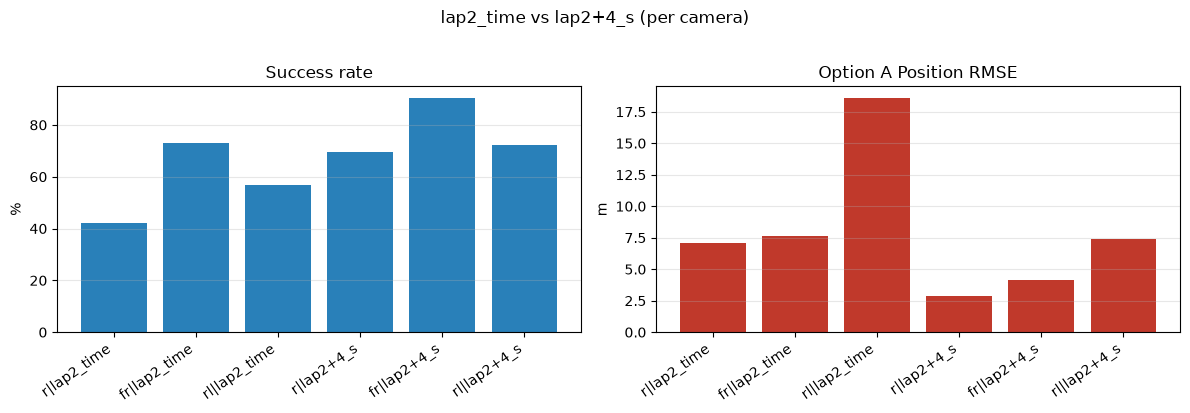

In [8]:
single_path = ROOT / "3d-map-test" / "outputs_hfnet" / "metrics_official.csv"
rows = []
if single_path.is_file():
    sdf = pd.read_csv(single_path)
    for cam in CAMERAS:
        sub = sdf[sdf["camera"] == cam] if "camera" in sdf.columns else sdf.iloc[0:0]
        if len(sub):
            r = sub.iloc[0].to_dict()
            r["run"] = f"{cam}|lap2_time"
            rows.append(r)
    print("=== single-lap ===")
    print(sdf[sdf["camera"].isin(CAMERAS)].to_string(index=False) if "camera" in sdf.columns else sdf)
else:
    print("no", single_path)

for cam in CAMERAS:
    r = runs[cam]["metrics"].copy()
    r["run"] = f"{cam}|lap2+4_s"
    rows.append(r)

cdf = pd.DataFrame(rows)
cdf.to_csv(OUT / "metrics_official_compare.csv", index=False)
print("\n=== compare table ===")
show = [c for c in ["run", "camera", "success_rate_%", "pos_rmse_xy_m", "pos_rmse_sn_m", "within_1m_%", "yaw_rmse_deg"] if c in cdf.columns]
print(cdf[show].to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("wrote", OUT / "metrics_official_compare.csv")

if len(cdf):
    labels = cdf["run"].tolist()
    xx = np.arange(len(labels))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(xx, pd.to_numeric(cdf["success_rate_%"], errors="coerce"), color="#2980b9")
    axes[0].set_xticks(xx); axes[0].set_xticklabels(labels, rotation=35, ha="right")
    axes[0].set_ylabel("%"); axes[0].set_title("Success rate")
    axes[0].grid(True, axis="y", alpha=0.3)
    axes[1].bar(xx, pd.to_numeric(cdf["pos_rmse_xy_m"], errors="coerce"), color="#c0392b")
    axes[1].set_xticks(xx); axes[1].set_xticklabels(labels, rotation=35, ha="right")
    axes[1].set_ylabel("m"); axes[1].set_title("Option A Position RMSE")
    axes[1].grid(True, axis="y", alpha=0.3)
    fig.suptitle("lap2_time vs lap2+4_s (per camera)", y=1.02)
    fig.tight_layout()
    fig.savefig(OUT / "metrics_vs_single_lap.png", dpi=150)
    print("saved", OUT / "metrics_vs_single_lap.png")
    plt.show()


## 5. Three-camera pose fusion (SFM_FEASIBILITY §10.5)

Fuse independent per-camera localization at **base_link pose level** (no feature fusion): hard select / SE(2) weighting + union oracle (GT upper bound).


load r: 1235  ok=857 (69.4%)
load fr: 1236  ok=1117 (90.4%)
load rl: 1236  ok=893 (72.2%)
fuse[hard] success 1191/1235  union_ok 1191  modes={'hard_select': 1191}
fuse[se2] success 1191/1235  union_ok 1191  modes={'se2_weighted': 906, 'single': 285}

--- complementarity (aligned to r) ---
  P(ok_r) = 69.4%
  P(ok_fr) = 90.4%
  P(ok_rl) = 72.2%
  P(union) = 96.4%
  P(fr|fail_r) = 77.8%
  P(rl|fail_r) = 48.1%

=== single vs fused ===
         camera  n_query  n_success  success_rate_%  pos_rmse_xy_m  lat_rmse_m  lon_rmse_m  pos_rmse_sn_m  s_rmse_m  n_rmse_m  yaw_rmse_deg  within_1m_%  within_1m_of_all_%
              r     1235        857          69.393          2.889       1.271       2.594          2.765     2.458     1.266         0.835       58.343              40.486
             fr     1236       1117          90.372          4.160       2.432       3.374          4.126     3.265     2.522         1.015       72.247              65.291
             rl     1236        893          

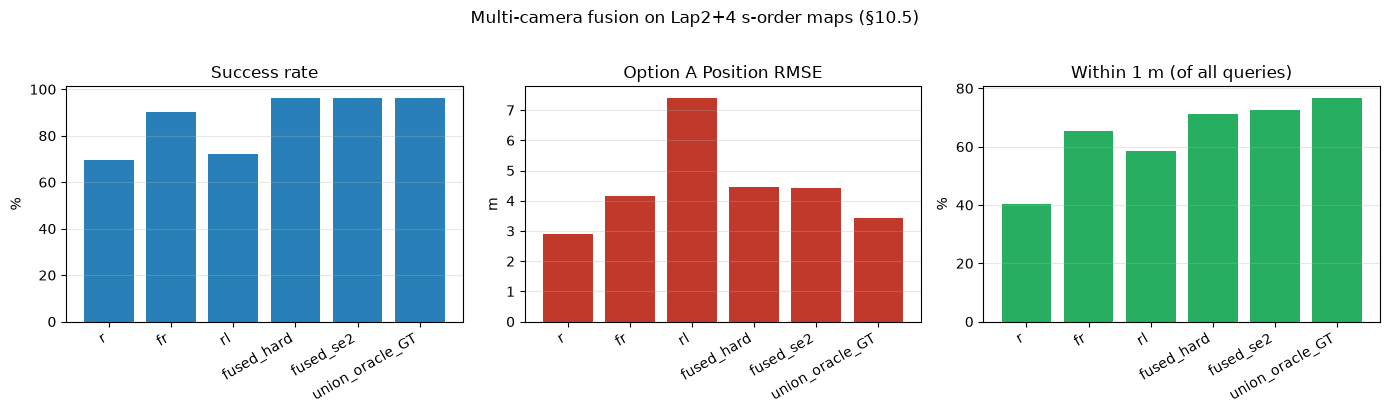

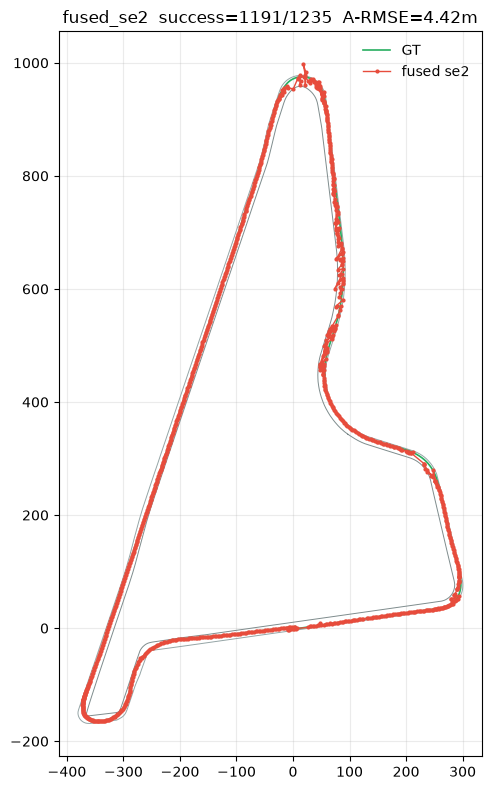

saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_fused
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_fused/err_vs_s_fused_se2.png


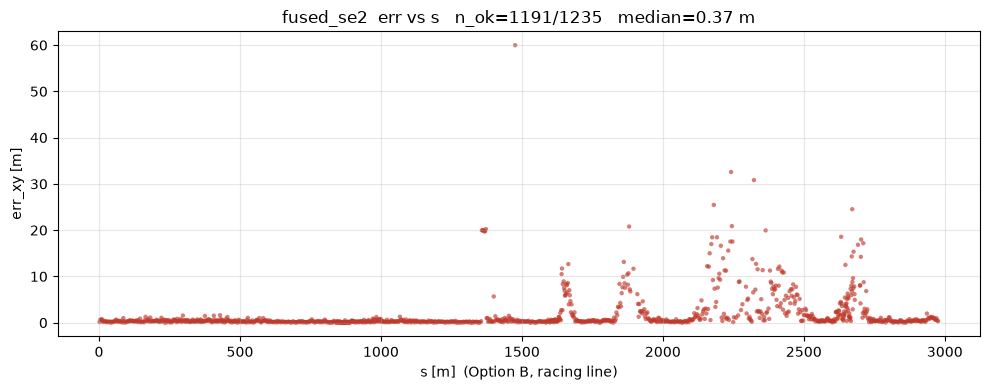

In [9]:
tables = {}
for cam in CAMERAS:
    p = OUT / f"loc_lap3_{cam}" / "errors.csv"
    df = pd.read_csv(p)
    need = {"stamp_ns", "ok", "gt_x", "gt_y", "gt_yaw", "pred_x", "pred_y", "pred_yaw", "n_pnp_inl"}
    miss = need - set(df.columns)
    if miss:
        raise RuntimeError(f"{p} missing {miss}")
    tables[cam] = df
    print(f"load {cam}: {len(df)}  ok={int(df.ok.sum())} ({100*df.ok.mean():.1f}%)")

fuse_dir = OUT / "loc_lap3_fused"
fuse_dir.mkdir(parents=True, exist_ok=True)

fused = {}
for mode in ("hard", "se2"):
    df_f = hf.fuse_multi_camera_tables(
        tables, ref_camera="r", mode=mode, gate_xy_m=5.0, gate_yaw_deg=15.0
    )
    df_f["t_rel_s"] = (df_f["stamp_ns"] - int(lap_q["start_ns"])) * 1e-9
    df_f.to_csv(fuse_dir / f"errors_{mode}.csv", index=False)
    fused[mode] = df_f
    print(
        f"fuse[{mode}] success {df_f.ok.sum()}/{len(df_f)}  "
        f"union_ok {df_f.union_ok.sum()}  modes={df_f.fuse_mode.value_counts().to_dict()}"
    )

df_a = fused["se2"]
ok_cols = [c for c in df_a.columns if c.startswith("ok_") and c != "ok"]
print("\n--- complementarity (aligned to r) ---")
for c in ok_cols:
    print(f"  P({c}) = {100*df_a[c].mean():.1f}%")
print(f"  P(union) = {100*df_a.union_ok.mean():.1f}%")
if "ok_fr" in df_a and (~df_a.ok_r).any():
    print(f"  P(fr|fail_r) = {100*df_a.loc[~df_a.ok_r, 'ok_fr'].mean():.1f}%")
if "ok_rl" in df_a and (~df_a.ok_r).any():
    print(f"  P(rl|fail_r) = {100*df_a.loc[~df_a.ok_r, 'ok_rl'].mean():.1f}%")


def metrics_from_df(df, name, times=None):
    ok = df["ok"].astype(bool).to_numpy()
    pred_xy = np.c_[df["pred_x"].to_numpy(float), df["pred_y"].to_numpy(float)]
    pred_yaw = df["pred_yaw"].to_numpy(float)
    gt_xy = np.c_[df["gt_x"].to_numpy(float), df["gt_y"].to_numpy(float)]
    gt_yaw = df["gt_yaw"].to_numpy(float)
    m = hf.compute_camloc_metrics(
        stamps_ns=df["stamp_ns"].to_numpy(),
        gt_xy=gt_xy,
        gt_yaw=gt_yaw,
        pred_xy=pred_xy,
        pred_yaw=pred_yaw,
        ok=ok,
        localize_times_s=times,
        map_mcap=MAP_MCAP,
    )
    m["camera"] = name
    return m

metric_rows = [metrics_from_df(tables[c], c) for c in CAMERAS]
for mode, df_f in fused.items():
    metric_rows.append(metrics_from_df(df_f, f"fused_{mode}"))

# union oracle (GT upper bound)
ref = tables["r"].sort_values("stamp_ns").reset_index(drop=True)
aligned = {"r": ref}
for c in CAMERAS:
    if c == "r":
        continue
    df = tables[c].sort_values("stamp_ns").reset_index(drop=True)
    ji = hf.align_by_nearest_stamp(ref["stamp_ns"].to_numpy(), df["stamp_ns"].to_numpy())
    aligned[c] = df.iloc[ji].reset_index(drop=True)

oracle_rows = []
for i in range(len(ref)):
    cands = []
    for c in CAMERAS:
        row = aligned[c].iloc[i]
        if bool(row.ok) and pd.notna(row.pred_x):
            cands.append(
                (float(row.err_xy), float(row.pred_x), float(row.pred_y), float(row.pred_yaw))
            )
    gx, gy, gyaw = float(ref.iloc[i].gt_x), float(ref.iloc[i].gt_y), float(ref.iloc[i].gt_yaw)
    if cands:
        cands.sort()
        _, px, py, pyaw = cands[0]
        err = float(np.hypot(px - gx, py - gy))
        ey = abs(((pyaw - gyaw + np.pi) % (2 * np.pi)) - np.pi) * 180 / np.pi
        oracle_rows.append(
            dict(
                stamp_ns=int(ref.iloc[i].stamp_ns),
                ok=True,
                gt_x=gx,
                gt_y=gy,
                gt_yaw=gyaw,
                pred_x=px,
                pred_y=py,
                pred_yaw=pyaw,
                err_xy=err,
                err_yaw_deg=ey,
            )
        )
    else:
        oracle_rows.append(
            dict(
                stamp_ns=int(ref.iloc[i].stamp_ns),
                ok=False,
                gt_x=gx,
                gt_y=gy,
                gt_yaw=gyaw,
                pred_x=np.nan,
                pred_y=np.nan,
                pred_yaw=np.nan,
                err_xy=np.nan,
                err_yaw_deg=np.nan,
            )
        )
df_or = pd.DataFrame(oracle_rows)
df_or.to_csv(fuse_dir / "errors_union_oracle.csv", index=False)
metric_rows.append(metrics_from_df(df_or, "union_oracle_GT"))

mdf_f = pd.DataFrame(metric_rows)
fcols = [
    "camera", "n_query", "n_success", "success_rate_%",
    "pos_rmse_xy_m", "lat_rmse_m", "lon_rmse_m",
    "pos_rmse_sn_m", "s_rmse_m", "n_rmse_m",
    "yaw_rmse_deg", "within_1m_%", "within_1m_of_all_%",
]
mdf_f = mdf_f[[c for c in fcols if c in mdf_f.columns]]
mdf_f.to_csv(fuse_dir / "metrics_fused.csv", index=False)
print("\n=== single vs fused ===")
print(mdf_f.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("wrote", fuse_dir / "metrics_fused.csv")
print("note: union_oracle_GT uses GT — upper bound only")

names = mdf_f["camera"].tolist()
x = np.arange(len(names))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(x, mdf_f["success_rate_%"], color="#2980b9")
axes[0].set_xticks(x); axes[0].set_xticklabels(names, rotation=30, ha="right")
axes[0].set_ylabel("%"); axes[0].set_title("Success rate")
axes[0].grid(True, axis="y", alpha=0.3)
axes[1].bar(x, mdf_f["pos_rmse_xy_m"], color="#c0392b")
axes[1].set_xticks(x); axes[1].set_xticklabels(names, rotation=30, ha="right")
axes[1].set_ylabel("m"); axes[1].set_title("Option A Position RMSE")
axes[1].grid(True, axis="y", alpha=0.3)
axes[2].bar(x, mdf_f["within_1m_of_all_%"], color="#27ae60")
axes[2].set_xticks(x); axes[2].set_xticklabels(names, rotation=30, ha="right")
axes[2].set_ylabel("%"); axes[2].set_title("Within 1 m (of all queries)")
axes[2].grid(True, axis="y", alpha=0.3)
fig.suptitle("Multi-camera fusion on Lap2+4 s-order maps (§10.5)", y=1.02)
fig.tight_layout()
fig.savefig(fuse_dir / "metrics_fuse_compare.png", dpi=150)
plt.show()

with open(sfm.EXTRACTED / "track_bounds.json") as f:
    tb = json.load(f)
tl = np.array([[p["x"], p["y"]] for p in tb["track_left"]["points"]], float)
trb = np.array([[p["x"], p["y"]] for p in tb["track_right"]["points"]], float)
df_f = fused["se2"]
ok = df_f.ok.to_numpy()
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(tl[:, 0], tl[:, 1], color="#7f8c8d", lw=0.7)
ax.plot(trb[:, 0], trb[:, 1], color="#95a5a6", lw=0.7)
ax.plot(df_f.gt_x, df_f.gt_y, color="#27ae60", lw=1.2, label="GT")
if ok.any():
    ax.plot(
        df_f.loc[ok, "pred_x"],
        df_f.loc[ok, "pred_y"],
        color="#e74c3c",
        lw=1.0,
        marker="o",
        ms=2,
        label="fused se2",
    )
ax.set_aspect("equal", adjustable="box")
ax.legend(frameon=False)
a_rmse = mdf_f.loc[mdf_f.camera == "fused_se2", "pos_rmse_xy_m"].iloc[0]
ax.set_title(f"fused_se2  success={ok.sum()}/{len(ok)}  A-RMSE={a_rmse:.2f}m")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(fuse_dir / "traj_fused_se2.png", dpi=140)
plt.show()
print("saved", fuse_dir)

# ensure racing line for Option B s
if "track" not in dir():
    lines = hf.load_racing_line(MAP_MCAP)
    track = lines["track"]


# --- fused_se2: err_xy vs Option B s (racing line) ---
df_f = fused["se2"]
ok_f = df_f.ok.astype(bool).to_numpy()
gx = df_f.gt_x.to_numpy(float)
gy = df_f.gt_y.to_numpy(float)
gyaw = df_f.gt_yaw.to_numpy(float)
ts = df_f.stamp_ns.to_numpy(np.int64)
if "err_xy" in df_f.columns:
    err = df_f.err_xy.to_numpy(float)
else:
    err = np.full(len(df_f), np.nan)
if not np.isfinite(err[ok_f]).any():
    err = np.hypot(df_f.pred_x.to_numpy(float) - gx, df_f.pred_y.to_numpy(float) - gy)

sg, ng, _, _ = track.xy_to_sn(gx[ok_f], gy[ok_f], gyaw[ok_f], ts[ok_f])
err_ok = err[ok_f]

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(sg, err_ok, s=10, c="#c0392b", alpha=0.65, edgecolors="none")
ax.set_xlabel("s [m]  (Option B, racing line)")
ax.set_ylabel("err_xy [m]")
ax.set_title(
    f"fused_se2  err vs s   n_ok={ok_f.sum()}/{len(ok_f)}   "
    f"median={np.nanmedian(err_ok):.2f} m"
)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(fuse_dir / "err_vs_s_fused_se2.png", dpi=150)
print("saved", fuse_dir / "err_vs_s_fused_se2.png")
plt.show()


## 6. Multi-Gaussian peak fit for $\sigma(s)$ (anti oversmoothing)

Model "mostly small along the track, few sharp peaks" as **baseline + $K$ periodic Gaussian peaks**:

$$
\sigma(s)=\sigma_0+\sum_{k=1}^{K} a_k\,\exp\!\left(-\frac{d_L(s,\mu_k)^2}{2w_k^2}\right),
\quad d_L=\min(|\cdot|,L-|\cdot|)
$$

**Changes vs older version (reduce good segments' $\sigma$ pulled up by spikes):**

1. Drop top 0.5% errors; use **circular bin MAD$\sigma$** as target (no wide-bandwidth NW on $e^2$)
2. Light smoothing on target ($h\approx 25\,\mathrm{m}$) to remove spikes only
3. **$K=5$ narrower peaks** (more overfit easily), `W_MAX≈70`, cap $\sigma_0$ (old: `K=4` / wide NW target / `W_MAX=250`)
4. Weighted LS: higher weight in peak regions; penalize $\hat\sigma>$ target in low-error regions to avoid raising valleys

Outputs: `sigma_multigauss_fit.npz`, `sigma_multigauss_vs_s.png`; then §7 exports `obs_error_sigma_vs_s.json` for EKF.


outlier clip: keep ≤ q100% = 20.787 m  kept 1185/1191  dropped 6
target=binMAD(w=35)+NW(h=22)  sigma0_init(q12%)=0.097  target med/p90=0.234/3.129
sigma0 bounds: [0.050, 0.181]
K=5  success=True  cost=12940.4110
sigma0=0.181 m  mean excess vs binMAD target: fit=0.047  oldNW80=1.883
  peak[0] mu= 1368.0 m  a=6.412  w=30.6 m
  peak[1] mu= 2181.9 m  a=6.257  w=46.7 m
  peak[2] mu= 2398.5 m  a=3.505  w=70.0 m
  peak[3] mu= 1873.2 m  a=3.251  w=39.6 m
  peak[4] mu= 1654.7 m  a=2.727  w=34.6 m
wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_fused/sigma_multigauss_fit.npz
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_fused/sigma_multigauss_vs_s.png
sigma_of_s samples: {0: 0.181, 500: 0.181, 1350: 5.573, 1800: 0.77, 2280: 1.705, 2700: 0.181}


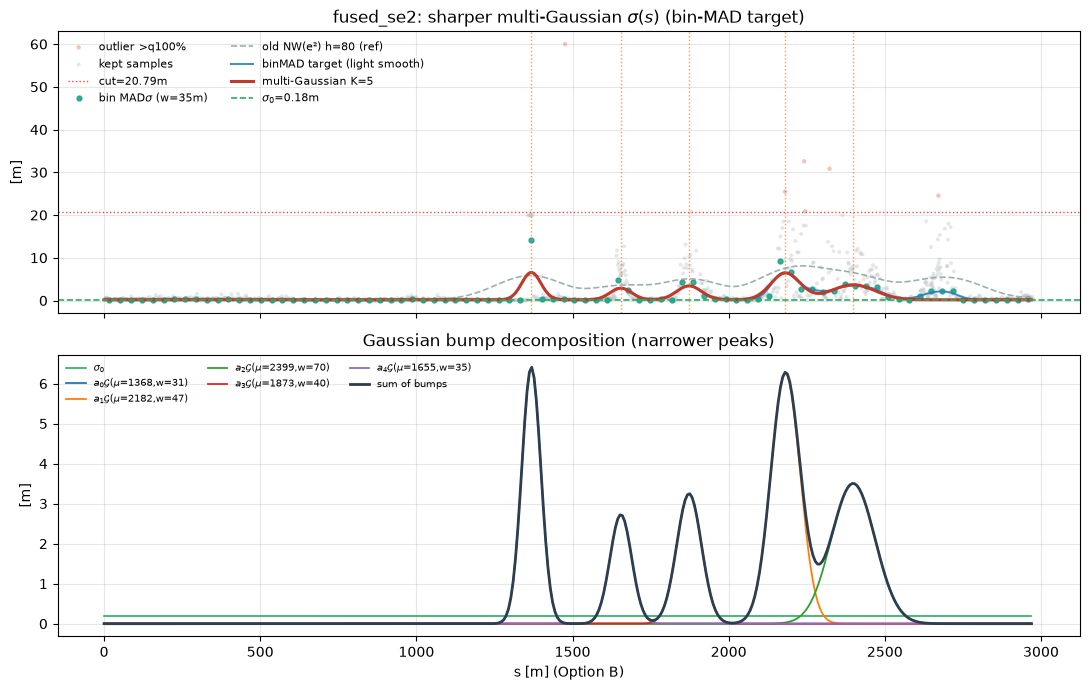

In [22]:

from scipy.optimize import least_squares

# --- inputs ---
if "fused" not in dir() or "se2" not in fused:
    raise RuntimeError("Run §5 first to obtain fused['se2']")
if "track" not in dir():
    track = hf.load_racing_line(MAP_MCAP)["track"]

df_f = fused["se2"]
ok_f = df_f.ok.astype(bool).to_numpy()
gx = df_f.gt_x.to_numpy(float)
gy = df_f.gt_y.to_numpy(float)
gyaw = df_f.gt_yaw.to_numpy(float)
ts = df_f.stamp_ns.to_numpy(np.int64)
if "err_xy" in df_f.columns:
    err = df_f.err_xy.to_numpy(float)
else:
    err = np.hypot(df_f.pred_x.to_numpy(float) - gx, df_f.pred_y.to_numpy(float) - gy)
if not np.isfinite(err[ok_f]).any():
    err = np.hypot(df_f.pred_x.to_numpy(float) - gx, df_f.pred_y.to_numpy(float) - gy)

L = float(track.lap)
s_all = np.mod(track.xy_to_sn(gx[ok_f], gy[ok_f], gyaw[ok_f], ts[ok_f])[0], L)
e_all = np.asarray(err[ok_f], dtype=float)

# --- hyperparams (sharper than previous NW h=80 / W_MAX=250 / K=4) ---
KEEP_Q = 0.995
K = 5
BIN_W_M = 35.0          # circular bin width for local MAD sigma
SMOOTH_H_M = 22.0       # light NW on bin MAD (not on raw e²)
N_GRID = 400
W_MIN, W_MAX = 12.0, 70.0
A_MAX = None
MIN_BIN_N = 8
SIGMA0_Q = 0.12         # baseline from low quantile of target
SIGMA0_Q_HI = 0.35      # hard cap on sigma0 during optimize
PEAK_W_BOOST = 2.5      # residual weight ~ 1 + boost*(target/med)
EXCESS_PENALTY = 3.0    # extra penalty when pred>target in low-error bins

e_cut = float(np.nanquantile(e_all, KEEP_Q))
keep = e_all <= e_cut
s_ok = s_all[keep]
e_ok = e_all[keep]
print(
    f"outlier clip: keep ≤ q{KEEP_Q:.0%} = {e_cut:.3f} m  "
    f"kept {keep.sum()}/{len(e_all)}  dropped {(~keep).sum()}"
)


def circ_dist(a, b, lap):
    d = np.abs(np.asarray(a) - np.asarray(b))
    return np.minimum(d, lap - d)


def nw_predict(s_query, s_train, y_train, h, lap):
    s_query = np.atleast_1d(np.asarray(s_query, dtype=float))
    s_train = np.asarray(s_train, dtype=float)
    y_train = np.asarray(y_train, dtype=float)
    out = np.empty(len(s_query), dtype=float)
    inv = 1.0 / max(h, 1e-6)
    for i, sq in enumerate(s_query):
        d = circ_dist(sq, s_train, lap)
        w = np.exp(-0.5 * (d * inv) ** 2)
        sw = w.sum()
        out[i] = np.nan if sw < 1e-12 else float(np.dot(w, y_train) / sw)
    return out


def circ_bin_mad_sigma(s, e, lap, bin_w, min_n=8):
    """Local robust sigma via circular bins: 1.4826 * MAD."""
    n_bin = max(int(np.ceil(lap / bin_w)), 8)
    edges = np.linspace(0.0, lap, n_bin + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    sig = np.full(n_bin, np.nan)
    cnt = np.zeros(n_bin, dtype=int)
    # assign (s near lap -> last bin)
    idx = np.clip(np.floor(np.mod(s, lap) / lap * n_bin).astype(int), 0, n_bin - 1)
    for b in range(n_bin):
        eb = e[idx == b]
        cnt[b] = len(eb)
        if len(eb) >= min_n:
            med = float(np.median(eb))
            mad = float(np.median(np.abs(eb - med)))
            sig[b] = 1.4826 * mad
    # fill empty bins from neighbors (circular)
    good = np.isfinite(sig)
    if not good.any():
        raise RuntimeError("no valid bins for MAD sigma")
    for b in range(n_bin):
        if good[b]:
            continue
        # nearest good bin on circle
        dist = circ_dist(centers[b], centers[good], lap)
        j = int(np.argmin(dist))
        sig[b] = sig[good][j]
    return centers, sig, cnt


def multi_gauss_sigma(s, theta, lap, k):
    """theta = [sigma0, mu_0..mu_{k-1}, log_a_0.., log_w_0..]"""
    s = np.atleast_1d(np.asarray(s, dtype=float))
    s0 = theta[0]
    mu = theta[1 : 1 + k]
    a = np.exp(theta[1 + k : 1 + 2 * k])
    w = np.exp(theta[1 + 2 * k : 1 + 3 * k])
    y = np.full(s.shape, s0, dtype=float)
    for i in range(k):
        y = y + a[i] * np.exp(-0.5 * (circ_dist(s, mu[i], lap) / w[i]) ** 2)
    return y


s_bin, sig_bin, bin_n = circ_bin_mad_sigma(s_ok, e_ok, L, BIN_W_M, min_n=MIN_BIN_N)
s_dense = np.linspace(0.0, L, N_GRID, endpoint=False)
# interpolate bin MAD onto dense grid, then light smooth
sig_dense_raw = nw_predict(s_dense, s_bin, sig_bin, max(BIN_W_M * 0.6, 20.0), L)
target = nw_predict(s_dense, s_dense, sig_dense_raw, SMOOTH_H_M, L)
target = np.clip(target, 1e-3, None)

# also keep old-style NW-on-e2 for comparison plot only
target_nw_e2 = np.sqrt(np.clip(nw_predict(s_dense, s_ok, e_ok**2, 80.0, L), 1e-6, None))

sigma0_init = float(np.nanquantile(target, SIGMA0_Q))
resid = np.clip(target - sigma0_init, 0.0, None)
print(
    f"target=binMAD(w={BIN_W_M:.0f})+NW(h={SMOOTH_H_M:.0f})  "
    f"sigma0_init(q{SIGMA0_Q:.0%})={sigma0_init:.3f}  "
    f"target med/p90={np.nanmedian(target):.3f}/{np.nanquantile(target,0.9):.3f}"
)

min_sep = L / (K * 2.8)
order = np.argsort(-resid)
mus = []
for idx in order:
    s_c = float(s_dense[idx])
    if all(circ_dist(s_c, m, L) >= min_sep for m in mus):
        mus.append(s_c)
    if len(mus) >= K:
        break
while len(mus) < K:
    mus.append(float(np.random.default_rng(0).uniform(0, L)))
mus = np.asarray(mus[:K], dtype=float)

a_init, w_init = [], []
for m in mus:
    d = circ_dist(s_dense, m, L)
    near = d < max(min_sep, 60.0)
    peak = float(resid[near].max()) if near.any() else float(resid.max())
    a_init.append(max(peak, 0.05))
    # half-width where residual drops to half peak (sharper init)
    half = near & (resid >= 0.5 * peak)
    if half.any():
        w_guess = float(np.quantile(d[half], 0.9))
    else:
        w_guess = 40.0
    w_init.append(float(np.clip(w_guess, W_MIN, W_MAX)))
a_init = np.asarray(a_init)
w_init = np.asarray(w_init)
if A_MAX is None:
    A_MAX = float(max(2.0, 1.8 * np.nanmax(target)))

theta0 = np.r_[sigma0_init, mus, np.log(a_init), np.log(w_init)]

tgt_med = float(np.nanmedian(target))
low_mask = target <= np.nanquantile(target, 0.40)
w_res = 1.0 + PEAK_W_BOOST * (target / max(tgt_med, 1e-6))


def pack_bounds(k, a_max, w_min, w_max):
    lo = np.r_[0.01, np.full(k, -np.inf), np.full(k, np.log(1e-3)), np.full(k, np.log(w_min))]
    hi = np.r_[a_max, np.full(k, np.inf), np.full(k, np.log(a_max)), np.full(k, np.log(w_max))]
    return lo, hi


def residuals(theta):
    th = theta.copy()
    th[1 : 1 + K] = np.mod(th[1 : 1 + K], L)
    pred = multi_gauss_sigma(s_dense, th, L, K)
    base = (pred - target) * w_res
    excess = np.maximum(pred - target, 0.0)
    base = base + EXCESS_PENALTY * excess * low_mask.astype(float)
    return base


lo, hi = pack_bounds(K, A_MAX, W_MIN, W_MAX)
lo[1 : 1 + K] = mus - L / 2
hi[1 : 1 + K] = mus + L / 2
# keep baseline near low-error regime; prevent optimizer from lifting sigma0 globally
hi[0] = float(max(sigma0_init * 1.5, np.nanquantile(target, SIGMA0_Q_HI)))
lo[0] = float(max(0.05, sigma0_init * 0.5))
print(f"sigma0 bounds: [{lo[0]:.3f}, {hi[0]:.3f}]")

res = least_squares(residuals, theta0, bounds=(lo, hi), max_nfev=3000)
th = res.x.copy()
th[1 : 1 + K] = np.mod(th[1 : 1 + K], L)
sigma_fit = multi_gauss_sigma(s_dense, th, L, K)
sigma0 = float(th[0])
mu_hat = th[1 : 1 + K]
a_hat = np.exp(th[1 + K : 1 + 2 * K])
w_hat = np.exp(th[1 + 2 * K : 1 + 3 * K])

# diagnostics vs old smooth target
infl_old = float(np.mean(np.maximum(target_nw_e2 - target, 0.0)))
infl_fit = float(np.mean(np.maximum(sigma_fit - target, 0.0)))
print(f"K={K}  success={res.success}  cost={res.cost:.4f}")
print(f"sigma0={sigma0:.3f} m  mean excess vs binMAD target: fit={infl_fit:.3f}  oldNW80={infl_old:.3f}")
for i in range(K):
    print(f"  peak[{i}] mu={mu_hat[i]:7.1f} m  a={a_hat[i]:.3f}  w={w_hat[i]:.1f} m")

fuse_dir = OUT / "loc_lap3_fused"
fuse_dir.mkdir(parents=True, exist_ok=True)
np.savez(
    fuse_dir / "sigma_multigauss_fit.npz",
    s_m=s_dense,
    sigma_m=sigma_fit,
    target_m=target,
    target_nw80_m=target_nw_e2,
    L=L,
    K=K,
    sigma0=sigma0,
    mu_m=mu_hat,
    a_m=a_hat,
    w_m=w_hat,
    theta=th,
    target_h_m=SMOOTH_H_M,
    bin_w_m=BIN_W_M,
    s_samples=s_ok,
    e_samples=e_ok,
    s_all=s_all,
    e_all=e_all,
    keep_q=KEEP_Q,
    e_cut_m=e_cut,
    s_bin_m=s_bin,
    sigma_bin_m=sig_bin,
    bin_n=bin_n,
)
print("wrote", fuse_dir / "sigma_multigauss_fit.npz")


def sigma_of_s(s_query):
    scalar = np.ndim(s_query) == 0
    sq = np.mod(np.atleast_1d(np.asarray(s_query, dtype=float)), L)
    out = multi_gauss_sigma(sq, th, L, K)
    return float(out[0]) if scalar else out


# --- plot ---
fig, axes = plt.subplots(2, 1, figsize=(11, 7.0), sharex=True)
ax = axes[0]
ax.scatter(s_all[~keep], e_all[~keep], s=10, c="#e74c3c", alpha=0.35, edgecolors="none", label=f"outlier >q{KEEP_Q:.0%}")
ax.scatter(s_ok, e_ok, s=8, c="#bdc3c7", alpha=0.40, edgecolors="none", label="kept samples")
ax.axhline(e_cut, color="#e74c3c", ls=":", lw=1.0, label=f"cut={e_cut:.2f}m")
ax.plot(s_bin, sig_bin, "o", ms=3.5, color="#16a085", alpha=0.85, label=fr"bin MAD$\sigma$ (w={BIN_W_M:.0f}m)")
ax.plot(s_dense, target_nw_e2, color="#95a5a6", lw=1.2, ls="--", alpha=0.9, label="old NW(e²) h=80 (ref)")
ax.plot(s_dense, target, color="#2980b9", lw=1.4, alpha=0.9, label="binMAD target (light smooth)")
ax.plot(s_dense, sigma_fit, color="#c0392b", lw=2.2, label=fr"multi-Gaussian K={K}")
ax.axhline(sigma0, color="#27ae60", ls="--", lw=1.2, label=fr"$\sigma_0$={sigma0:.2f}m")
for m in mu_hat:
    ax.axvline(m, color="#e67e22", ls=":", lw=1.0, alpha=0.75)
ax.set_ylabel("[m]")
ax.set_title("fused_se2: sharper multi-Gaussian $\\sigma(s)$ (bin-MAD target)")
ax.legend(frameon=False, ncol=2, fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(s_dense, np.full_like(s_dense, sigma0), color="#27ae60", lw=1.2, label=r"$\sigma_0$")
for i in range(K):
    bump = a_hat[i] * np.exp(-0.5 * (circ_dist(s_dense, mu_hat[i], L) / w_hat[i]) ** 2)
    ax.plot(s_dense, bump, lw=1.3, label=fr"$a_{i}\mathcal{{G}}$($\mu$={mu_hat[i]:.0f},w={w_hat[i]:.0f})")
ax.plot(s_dense, sigma_fit - sigma0, color="#2c3e50", lw=2.0, label=r"sum of bumps")
ax.set_xlabel("s [m] (Option B)")
ax.set_ylabel("[m]")
ax.set_title("Gaussian bump decomposition (narrower peaks)")
ax.legend(frameon=False, ncol=3, fontsize=7)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(fuse_dir / "sigma_multigauss_vs_s.png", dpi=150)
print("saved", fuse_dir / "sigma_multigauss_vs_s.png")
print("sigma_of_s samples:", {s: round(sigma_of_s(s), 3) for s in (0, 500, 1350, 1800, 2280, 2700)})
plt.show()


## 7. Export observation error function $\sigma(s)$

Write reusable artifacts from current `sigma_multigauss_fit.npz`:

| File | Purpose |
|---|---|
| `obs_error_sigma_vs_s.csv` | dense table $s\mapsto\sigma$ |
| `obs_error_sigma_vs_s.json` | closed-form params ($\sigma_0,\{\mu_k,a_k,w_k\}$) |
| `3d-map-test/obs_error_sigma_s.py` | `sigma_of_s(s)` entry point |


wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_fused/obs_error_sigma_vs_s.csv
wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_fused/obs_error_sigma_vs_s.json
module /Users/hbai/SchubKI/PixelRacers/3d-map-test/obs_error_sigma_s.py exists True

=== sigma(s) samples ===
  s=     0.0 m  ->  sigma= 0.181 m
  s=   330.8 m  ->  sigma= 0.181 m
  s=   661.5 m  ->  sigma= 0.181 m
  s=   992.3 m  ->  sigma= 0.181 m
  s=  1323.1 m  ->  sigma= 2.360 m
  s=  1653.8 m  ->  sigma= 2.907 m
  s=  1984.6 m  ->  sigma= 0.245 m
  s=  2315.3 m  ->  sigma= 2.016 m
  s=  2646.1 m  ->  sigma= 0.188 m
saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_fused/obs_error_sigma_vs_s.png


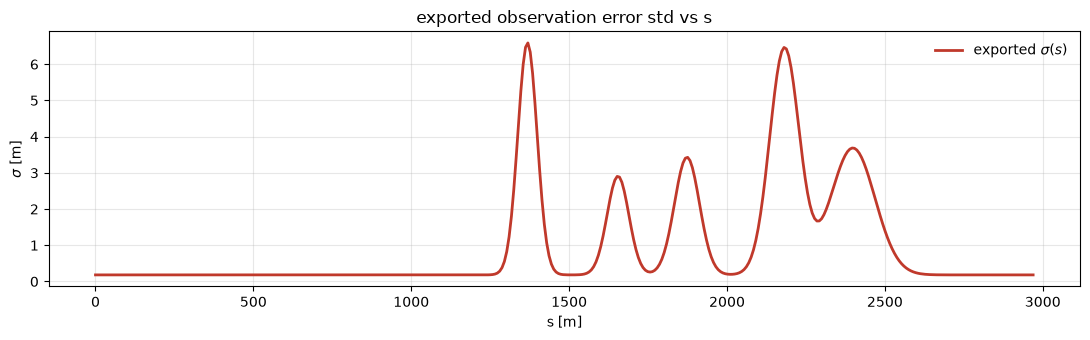

In [23]:

import json
from pathlib import Path

fit_path = OUT / "loc_lap3_fused" / "sigma_multigauss_fit.npz"
if not fit_path.is_file():
    raise FileNotFoundError(f"Run §6 first to generate {fit_path}")

d = np.load(fit_path, allow_pickle=True)
L = float(d["L"])
K = int(d["K"])
sigma0 = float(d["sigma0"])
mu = d["mu_m"].astype(float)
a = d["a_m"].astype(float)
w = d["w_m"].astype(float)
s_m = d["s_m"].astype(float)
sigma_m = d["sigma_m"].astype(float)
tgt = d["target_m"].astype(float) if "target_m" in d.files else np.full_like(sigma_m, np.nan)

fuse_dir = fit_path.parent
csv_path = fuse_dir / "obs_error_sigma_vs_s.csv"
with open(csv_path, "w") as f:
    f.write("s_m,sigma_m,target_m\n")
    for s, sig, t in zip(s_m, sigma_m, tgt):
        f.write(f"{s:.6f},{sig:.6f},{t:.6f}\n")

params = {
    "model": "periodic_multi_gaussian",
    "description": "Observation position error std vs racing-line s (fused_se2).",
    "formula": "sigma(s)=sigma0+sum_k a_k*exp(-0.5*d_L(s,mu_k)^2/w_k^2)",
    "units": {"s": "m", "sigma": "m"},
    "L_m": L,
    "K": K,
    "sigma0_m": sigma0,
    "peaks": [{"mu_m": float(mu[i]), "a_m": float(a[i]), "w_m": float(w[i])} for i in range(K)],
    "fit_meta": {
        "source_npz": str(fit_path),
        "keep_q": float(d["keep_q"]) if "keep_q" in d.files else None,
        "e_cut_m": float(d["e_cut_m"]) if "e_cut_m" in d.files else None,
        "target_h_m": float(d["target_h_m"]) if "target_h_m" in d.files else None,
        "bin_w_m": float(d["bin_w_m"]) if "bin_w_m" in d.files else None,
        "n_grid": int(len(s_m)),
    },
}
json_path = fuse_dir / "obs_error_sigma_vs_s.json"
json_path.write_text(json.dumps(params, indent=2))

# sync callable module
mod_path = ROOT / "3d-map-test" / "obs_error_sigma_s.py"
print("wrote", csv_path)
print("wrote", json_path)
print("module", mod_path, "exists", mod_path.is_file())

# reload helper
import importlib
import sys
sys.path.insert(0, str(ROOT / "3d-map-test"))
import obs_error_sigma_s as oes
oes = importlib.reload(oes)
oes.load_params(json_path)

print("\n=== sigma(s) samples ===")
for s in np.linspace(0, L, 9, endpoint=False):
    print(f"  s={s:8.1f} m  ->  sigma={oes.sigma_of_s(s):6.3f} m")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(s_m, sigma_m, color="#c0392b", lw=2.0, label=r"exported $\sigma(s)$")
ax.set_xlabel("s [m]"); ax.set_ylabel(r"$\sigma$ [m]")
ax.set_title("exported observation error std vs s")
ax.legend(frameon=False); ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(fuse_dir / "obs_error_sigma_vs_s.png", dpi=140)
print("saved", fuse_dir / "obs_error_sigma_vs_s.png")
plt.show()


## Tuning

| Parameter | Description |
|---|---|
| `CAMERAS` | default `r, fr, rl` |
| `POLYGONS` | `fr` car-body mask |
| `OVERRIDE_MAP` | `True` forces map rebuild |
| `OVERRIDE_QUERY` | `True` forces query rerun |
| `MAP_STRIDE` / `QUERY_STRIDE` | use `2` for smoke tests |
| `NEIGHBOR_MODE` | `arc` / `index` |
| §6 `K` / `BIN_W_M` / `W_MAX` | peak count / bin MAD width / peak width cap (lower `W_MAX` if peaks are too wide) |

Dirs: `outputs_hfnet_multi_lap_s/map_{cam}_lap2+4/`, `loc_lap3_{cam}/`, `loc_lap3_fused/`.
